# **A. Root finding for scalar nonlinear equations**

In [2]:
# import all the packages here
import numpy as np
import matplotlib.pyplot as plt


In [3]:
# Function that finds the fixed point of a certain function phi
#
#
# INPUT:
# phi           iteration function (function handle)
# x0            initial guess for the root
# tol           desired tolerance to stop iterations
# maxit         maximum number of iterations
#
# OUTPUT:
# x             solution at the final iteration
# success       true means converged according to error estimator
# errEst        array with error estimate per iterations
# xHist         array with solutions per iterations

def fpIterator(phi, x0, maxit, tol=1e-8):

    # initialize your output variables here (x, errEst, xHist)
    x = x0
    errEst = []
    xHist = []

    # loop (at most maxit iterations) to find the root; possible strategies
    for i in range(maxit):
    # check for convergence, i.e. check if the error at the current iteration
    # reached the tolerance
        xHist.append(x)
        if np.linalg.norm(phi(x) - x) <= tol:
            success = True
            break   # if yes >>> break
        else:     # if no >>> update the previous iteration x and iterate again
            success = False
            errEst.append(np.linalg.norm(phi(x) - x))
            x = phi(x)   # inside the loop you will have to compute the new guess for the root and

    return x, success, errEst, xHist


In [4]:
## Discussion question A.1(a)

# defining phi, x0, tol and maxit 

phi = lambda x: (-1) / (x ** 2 - 2 )
print('FP iteration results:\n')
for i in [-2, -1.75, -1.5, -1.25, -1, 0.75, 0.5, -0.25, 0, 0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2 ]:
  x, success, errEst, xHist = fpIterator(phi, i, tol=1e-6, maxit=20)


#  adding a print line
  if success:
        print(f'x0 = {i} converged to {x} in {len(xHist)} iterations.')
  else:
        print(f'x0 = {i} failed to converge. Iterations:{len(xHist)}')

  print('----------------------------------------------------')


FP iteration results:

x0 = -2 converged to 0.6180328713933071 in 17 iterations.
----------------------------------------------------
x0 = -1.75 failed to converge. Iterations:20
----------------------------------------------------
x0 = -1.5 converged to 0.6180328801801785 in 19 iterations.
----------------------------------------------------
x0 = -1.25 converged to 0.6180330557458682 in 19 iterations.
----------------------------------------------------
x0 = -1 converged to 1.0 in 2 iterations.
----------------------------------------------------
x0 = 0.75 converged to 0.6180352841429142 in 17 iterations.
----------------------------------------------------
x0 = 0.5 converged to 0.6180328713933071 in 16 iterations.
----------------------------------------------------
x0 = -0.25 converged to 0.6180329864054391 in 17 iterations.
----------------------------------------------------
x0 = 0 converged to 0.6180328713933071 in 17 iterations.
--------------------------------------------------

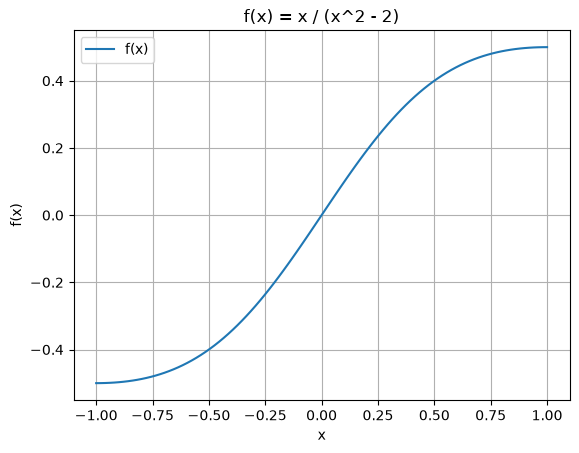

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data: 'DataParamType' = None, **kwargs) -> 'list[Line2D]'>

In [5]:
# Function that finds the solution of an equation or system of equations using the Newton method
#
# INPUT:
# f             function handling (may be vector valued)
# df            derivative of f (or function returning Jacobian matrix)
# x0            initial guess
# tol           desired toleraance to stop iterations
# maxit         maximum number of iterations
#
# OUTPUT:
# x             solution at the final iteration
# success       true means converged according to error estimator
# errEst        array with error estimate per iterations
# xHist         array with solutions per iterations
#

def newton(f, df, x0, tol=1e-8, maxit = 20):
    x = x0

    phi = lambda x: x - f(x) / df(x)

    x, success, errEst, xHist = fpIterator(phi, x, tol = 1e-30, maxit = 20)

    return x, success, errEst, xHist



f = lambda x: x / ((x ** 2) +1 )
df = lambda x: ( 1- (x ** 2) ) / (((x ** 2) +1 ) ** 2)

x, succes, errEst, xHist = newton(f,df,0.2)
plt.plot(np.linspace(-1, 1, 100) , f(np.linspace(-1, 1, 100)), label = 'f(x)')
plt.title(f'f(x) = x / (x^2 - 2)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid()
plt.show()
plt.plot

[0.57, -0.5486387201896014, 0.4725142886060517, -0.2716468140004017, 0.04328478964196031, -0.00016249888112841726]
[0.2, -0.01666666666666669, 9.261831990365482e-06, -1.5889880692699157e-15, 0.0]
[0.58, -0.5880409885473178, 0.621637317395742, -0.7830314448205599, 2.482057307414223, 5.9260388988882315]


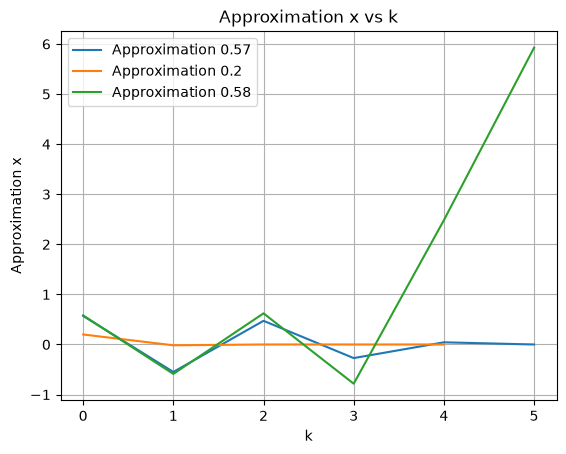

In [6]:
## Discussion question a.)

# set up inputs and initial guesses
f = lambda x: x / (1+ (x ** 2))
df = lambda x: ( (1 - (x ** 2))) / (((x ** 2) +1 ) ** 2)

for i in [0.57, 0.2, 0.58]: #showing 0.58 doesnt work anymore

    x, succes, errEst, xHist = newton(f,df,i)

    if len(xHist) <= 6:
        kList = np.arange(len(xHist))
    else:
        kList = np.arange(6)
        xHist = xHist[0:6]
    print(xHist)
    plt.plot(kList, xHist, label= f'Approximation {i}')
    plt.title('Approximation x vs k')
    plt.xlabel('k')
    plt.ylabel('Approximation x')
    plt.grid(True)
    plt.legend()



# **B. Root finding for systems of nonlinear equations**

In [7]:
f = lambda x: x**3 -2*x+1
df = lambda x: 3*x**2 -2

x, succes, errEst, xHist = newton(f,df,0.25, tol= 10**(-12))
print(x, succes, errEst, xHist)


0.6180339887498948 True [np.float64(0.2844827586206897), np.float64(0.07324783641989141), np.float64(0.010085180971142305), np.float64(0.00021810949278133762), np.float64(1.0324536692252195e-07), np.float64(2.3092638912203256e-14)] [0.25, 0.5344827586206897, 0.6077305950405811, 0.6178157760117234, 0.6180338855045048, 0.6180339887498717, 0.6180339887498948]


In [8]:
## Discussion question b.)

# - set the correct inputs and find the root

x, succes, errEst, xHist = newton(f,df,0.25, tol= 10**(-12))

# take the last iteration instead of limit

print(len(xHist))
print(xHist)

k =  len(xHist) - 2
p = np.log((errEst[k]) / (errEst[k - 1])) / (np.log((errEst[k - 1]) / (errEst[k - 2])))
asymptFactor = (errEst[k - 1]) / ((errEst[k - 2]) ** 2)

# computing order and asymptotic factor

print('\n\nConvergence order results: \n')
print(f'    method    k = {k}        order = {p}    factor = {asymptFactor}')
print('----------------------------------------------------')
print(asymptFactor == 6 / p)
print(6 * 0.61803 / p)


7
[0.25, 0.5344827586206897, 0.6077305950405811, 0.6178157760117234, 0.6180338855045048, 0.6180339887498717, 0.6180339887498948]


Convergence order results: 

    method    k = 5        order = 2.0002373119688124    factor = 2.170308325772571
----------------------------------------------------
False
1.8538700272269582


In [9]:
## Discussion question B.2


def newtonNonlienar(F, J, x0, maxit, tol=1e-8):  # nonlinear version of Newton method
    x = x0

    phi = lambda x: x - np.matmul(np.linalg.inv(J(x)), F(x))

    x, success, errEst, xHist = fpIterator(phi, x, maxit, tol = 1e-8)

    return x, success, errEst, xHist


#############  define F(x) and J(x)
x0 = np.array([0, 0])
A = np.array([[2 ,- 1], [- 1, 2 ]])
b = np.array([1, 0])

# F needs to be full rank - > J is full rank - > there is an inverse of J

F = lambda x: np.matmul(A, x) - b
J = lambda x: A

# computing solutions with errors


x, success, errEst, xHist = newtonNonlienar(F, J, x0, tol = 1e-6, maxit =20)

print(np.matmul(A, x) == b) # checking if the solution is correct
print(x)
print(xHist)
print(errEst)



[ True  True]
[0.66666667 0.33333333]
[array([0, 0]), array([0.66666667, 0.33333333])]
[np.float64(0.7453559924999298)]


In [ ]:
## THIS FUNCTION IS GIVEN TO THE STUDENTS

# plotResidual_partB
#
# INPUT
# p         parameter which shifts the parabola

def plotResidual_partB(p):

    plt.figure(figsize=(18,10))

    nHat = np.array([0.5, 1])
    nHat = nHat/np.linalg.norm(nHat)
    tHat = np.array([nHat[1], -nHat[0]])
    xHat = np.array([[2],[1]])/np.sqrt(2)

    # For plotting the curves we parametrize them using angle (F1) and tangential co-ordinate (F2)
    par1 = lambda theta, p:  np.array([[2*np.cos(theta)], [np.sin(theta)]])
    par2 = lambda t, p: np.outer((tHat), t) + np.outer( (nHat), (np.matmul(nHat,xHat) + (p+0.5*np.power(t-np.matmul(tHat,xHat), 2)) ) )
    parametrizations = [par1, par2]

    paramRanges = [[0, 2*np.pi], [-1, 2.5]]
    paramStyles = ['r-','r--']

    N = 100
    xLim = [-5, 5]
    yLim = [-2.5, 3.5]

    # Plot contours of the error
    xVals = np.linspace(xLim[0], xLim[1], N)
    yVals = np.linspace(yLim[0], yLim[1], N)
    X, Y = np.array( np.meshgrid(xVals, yVals, indexing='xy') )

    s1 = lambda x,y: np.power( np.power(x/2, 2) + np.power(y, 2) - 1, 2)
    s2 = lambda x,y: np.power( nHat[0]*x + nHat[1]*y -np.matmul(nHat, xHat) - (p+0.5*np.power( (tHat[0]*x+tHat[1]*y-np.matmul(tHat, xHat)),2 )) ,2 )
    errFun = lambda x, y: np.sqrt(s1(x,y) + s2(x,y))
    Z = np.log10(errFun(X, Y))

    levels = np.arange(-2, 1, 0.25)
    plt.contourf( xVals, yVals, Z, levels )

    # Add parametrized curves
    i = 0
    for pdx in parametrizations:
        params = np.linspace(paramRanges[i][0], paramRanges[i][1], N)
        xyCoords = pdx(params, p)

        if i == 1:
            x = xyCoords[0, :]
            y = xyCoords[1, :]
        else:
            x = xyCoords[0, :][0]
            y = xyCoords[1, :][0]

        plt.plot(x, y, paramStyles[i])

        i += 1

    plt.colorbar()
    plt.xlabel('$x_1$', fontsize=16)
    plt.ylabel('$x_2$', fontsize=16)
    plt.title('Colormap corresponds to $\log_{{10}}\sqrt{{F_1^2 + F_2^2}}$, where $p = %4.2f $' % p, fontsize=16)

    ## END OF A FUNCTION GIVEN TO THE STUDENTS


z = [1.41421356 0.70710678]
n = [0.4472136  0.89442719]
t = [ 0.89442719 -0.4472136 ]
Initial guesses x = [[4.09749514 1.60153397]
 [0.51978637 3.39038835]]
EXPLORE THE CONVERGENCE OF THE METHOD

    p = -0.5     x0 = [4.09749514 1.60153397]      success = True   iter 7    order = 2.051719011367711
Converged solution: [1.96985514 0.17296728]
Error estimates: [np.float64(1.5507221021739839), np.float64(0.8433489880130344), np.float64(0.2517629867588087), np.float64(0.027946112141902412), np.float64(0.0005553039292477357), np.float64(1.79033587632242e-07)]
History of approximations: [array([4.09749514, 1.60153397]), array([3.0040465, 0.501939 ]), array([2.24319513, 0.13814962]), array([1.99200076, 0.15506091]), array([1.9703672 , 0.17275198]), array([1.96985529, 0.17296718]), array([1.96985514, 0.17296728])]
---------------------------------------------------------
EXPLORE THE CONVERGENCE OF THE METHOD

    p = -0.5     x0 = [0.51978637 3.39038835]      success = True   iter 7    order =

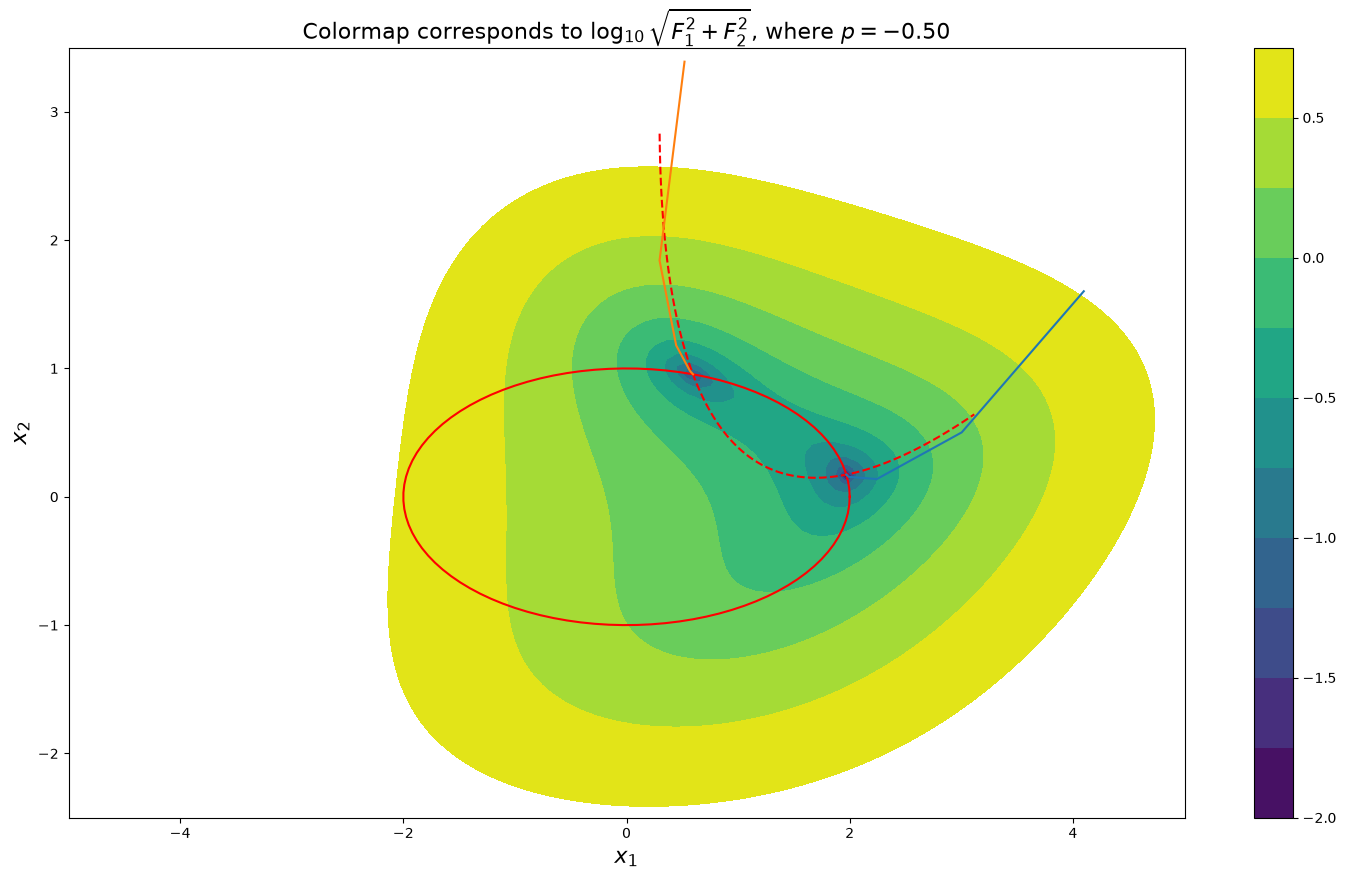

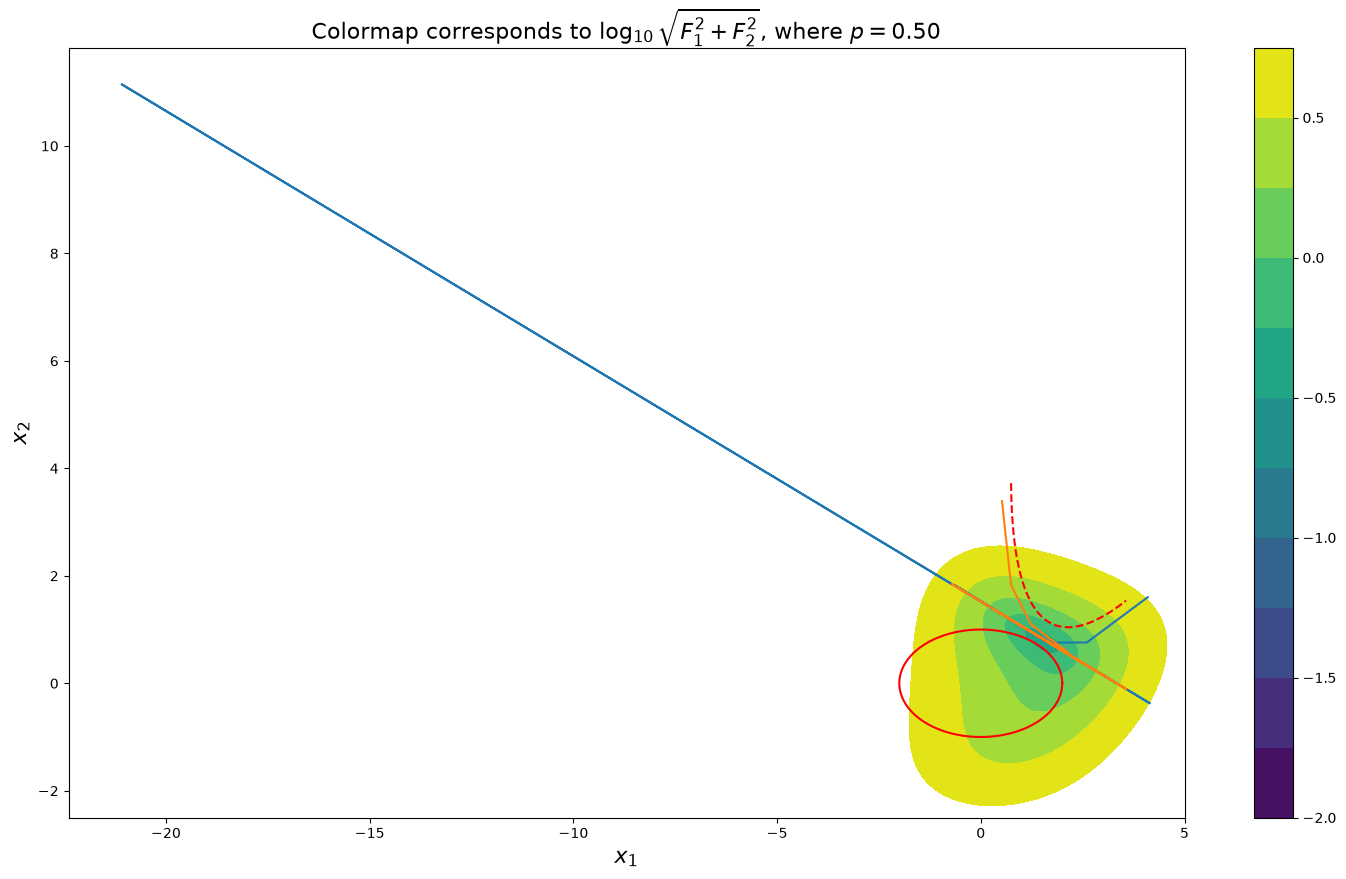

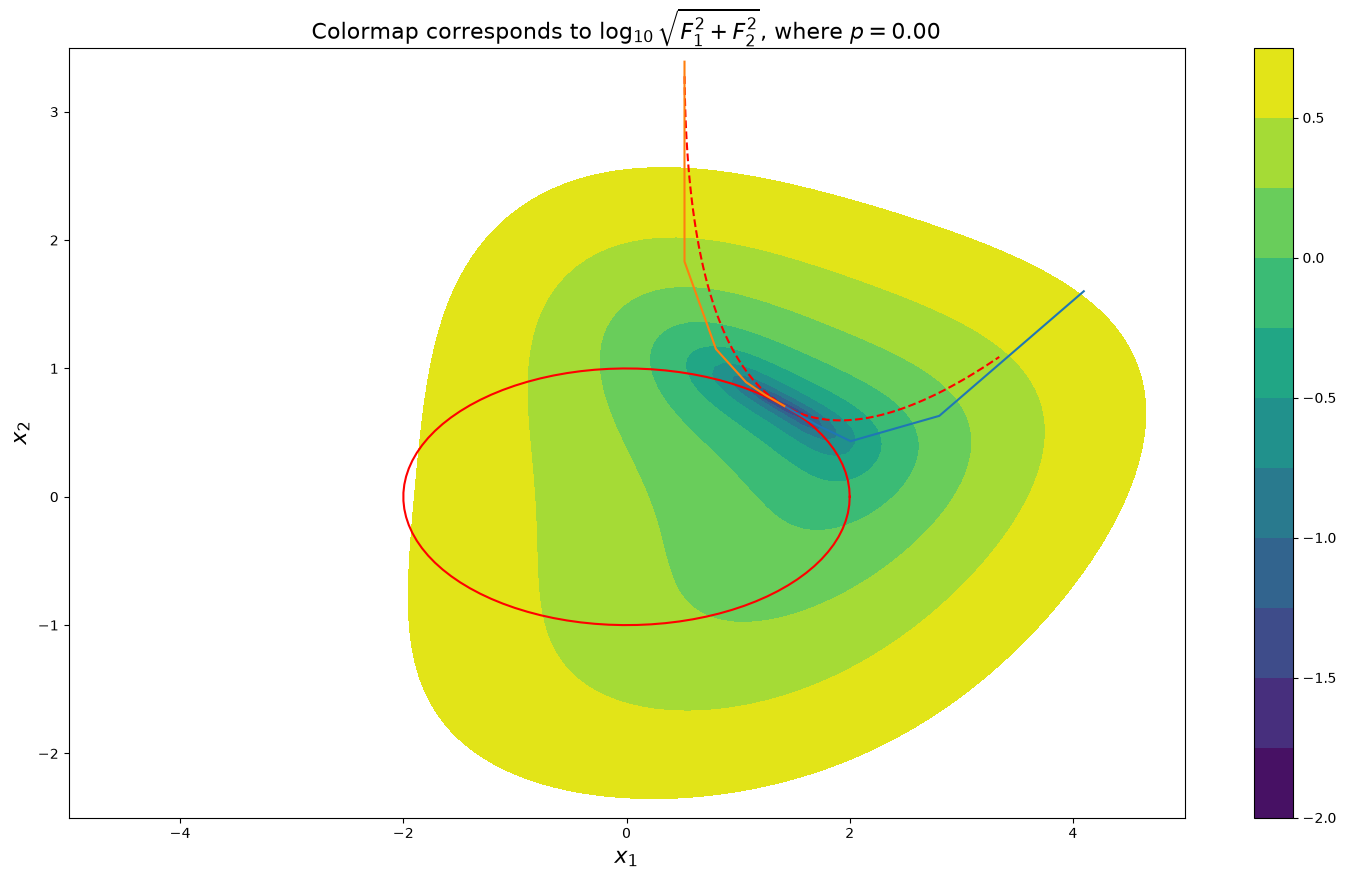

In [11]:

z = np.array([(1/ np.sqrt(2)) * 2, (1/ np.sqrt(2)) * 1])


F1 = lambda x: ((x[0]/2)**2 + x[1] ** 2 - 1)
J1 = lambda x: np.array([x[0] / 2, 2*x[1]])
print(f'z = {z}')

n = J1(z) / np.linalg.norm(J1(z))
print(f'n = {n}')

t = np.array([n[1], -n[0]])
print(f't = {t}')

# These are the two initial guesses as per the problem description
xInitial = np.array([z + 2*(n + t), z + 2*(n - t)])

print(f'Initial guesses x = {xInitial}')

F2 = lambda x: (np.matmul(n, x - z) - p - (1/2) * (np.matmul(t, x - z)) ** 2)
J2 = lambda x: np.array(n - (np.matmul(t, x - z)) * t)


# Corrected F and J to return numerical arrays
F = lambda x: np.array([F1(x), F2(x)])
J = lambda x: np.array([J1(x), J2(x)])



# Use the first initial guess from x_initial_guesses

pList = [-0.5, 0.5, 0]
for p in pList:
  plotResidual_partB(p)
  history = []
  history1 = []
  history2 = []
  for i in range(0, 2):
    x0 = xInitial[i]

    x, success, errEst, xHist = newtonNonlienar(F, J, x0, tol = 1e-8, maxit=30)
    k =  len(xHist) - 2
    order = np.log((errEst[k]) / (errEst[k - 1])) / (np.log((errEst[k - 1]) / (errEst[k - 2])))

    history.append(xHist)

    # print out the results as follows (or in a similar and readable way)
    print('EXPLORE THE CONVERGENCE OF THE METHOD')
    print(f'\n    p = {p}     x0 = {x0}      success = {success}   iter {len(xHist)}    order = {order}')
    print(f'Converged solution: {x}')
    print(f'Error estimates: {errEst}')
    print(f'History of approximations: {xHist}')
    print('---------------------------------------------------------')

  for i in range(2):
      xHist_i = history[i]

      history1 = []
      history2 = []
      for j in range(len(xHist_i)):
          history1.append(xHist_i[j][0])
          history2.append(xHist_i[j][1])

      plt.plot(history1, history2)



